In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/titanic/train.csv
/kaggle/input/competitions/titanic/test.csv
/kaggle/input/competitions/titanic/gender_submission.csv


## **Reading the Data**

In [2]:
train_df = pd.read_csv('../input/competitions/titanic/train.csv')

In [3]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


- .info를 사용하면 표면 수준에서 데이터를 조사하는 빠른 방법. 이제 각 열의 이름과 해당 열에 몇 개의 값이 있는지 확인할 수 있음
- 세 개의 열인 Age, Cabin, Embarked에 몇 개의 값이 누락되어 있음을 확인
- 때로는 데이터를 훈련할 때 어떤 열이 가장 유익한지 확인하기 위해 한 줄 전체를 살펴보는 것이 유용

In [4]:
train_df.loc[0]

PassengerId                          1
Survived                             0
Pclass                               3
Name           Braund, Mr. Owen Harris
Sex                               male
Age                               22.0
SibSp                                1
Parch                                0
Ticket                       A/5 21171
Fare                              7.25
Cabin                              NaN
Embarked                             S
Name: 0, dtype: object

- 먼저, 이름 범주를 삭제하면 Survived 범주에는 아무런 결과도 없을 것이라는 점을 확인
- Ticket 클래스도 그다지 유용하지 않음
- Ticket 클래스를 포함하면 순수한 숫자가 아닌 경우가 많기 때문에 범주형이 될 수 있다는 점을 유의
- PassengerId도 유용한 정보를 제공하지 않으므로 삭제
- 누락된 값이 많은 Cabin을 사용하지 않음

In [5]:
#Drop Name and Ticket

train_df.drop(['Name', 'Ticket', 'PassengerId', 'Cabin'], axis=1, inplace=True)
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Survived  891 non-null    int64  
 1   Pclass    891 non-null    int64  
 2   Sex       891 non-null    object 
 3   Age       714 non-null    float64
 4   SibSp     891 non-null    int64  
 5   Parch     891 non-null    int64  
 6   Fare      891 non-null    float64
 7   Embarked  889 non-null    object 
dtypes: float64(2), int64(4), object(2)
memory usage: 55.8+ KB


- 다음으로 진행하기 전에 train_df를 X와 y로 분할하여 훈련 데이터를 준비

In [6]:
X = train_df.drop('Survived', axis=1, inplace=False)
y = train_df['Survived']

print(f'Input features shape: {X.shape}')
print(f'Labels shape: {y.shape}')

Input features shape: (891, 7)
Labels shape: (891,)


## **Data Analysis**

In [7]:
#Import visualization libraries

import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns

- 타깃 변수의 데이터 불균형 확인

Text(0, 0.5, 'Number of Passengers')

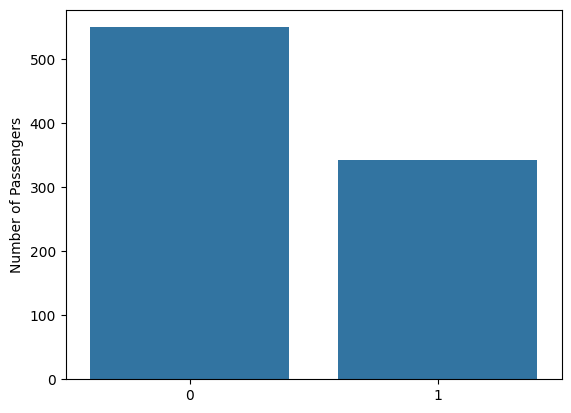

In [8]:
sns.barplot(x = y.unique(), y = y.value_counts())
plt.ylabel('Number of Passengers')

   Pclass  Sex  Age  SibSp  Parch  Fare  Embarked
0     891  891  714    891    891   891       889


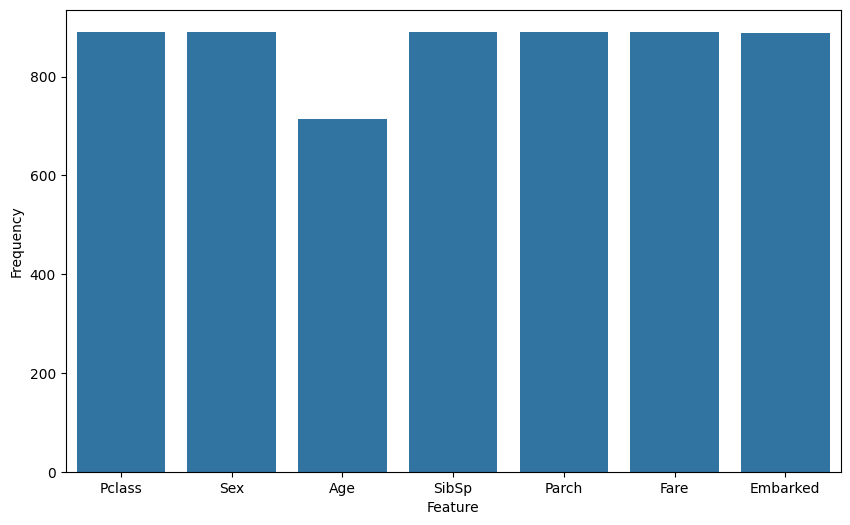

In [9]:
frequencies = X.count()

freq_df = pd.DataFrame([frequencies], columns=X.columns)
print(freq_df.head())

plt.figure(figsize=(10, 6))
sns.barplot(x=X.columns, y = frequencies)
plt.ylabel('Frequency')
plt.xlabel('Feature')
plt.show()

- 연령 카테고리에 상당한 수의 누락된 값이 있다는 것이 분명
- 나열된 값들 중에서 Embarked는 추가로 2개의 값이 누락되어 있음
- 여기서 Sci-kit Learn은 간단한 임퓨터로 이러한 누락 값을 보충하는 좋은 그리고 쉬운 방법을 제공
  
## **Imputing and One-Hot Encoding**

Imputing: 결함 값을 처리하는 과정
- 이 과제를 극복하는 가장 기본적인 방법은 결함 값을 포함하는 모든 사례/행을 제거하는 것
- 그러나 그렇게 하면 891보다 훨씬 적은 714개의 학습 사례만 남게 됨
- 따라서 SimpleImputer API를 사용

In [10]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

'''
The following pipeline is only for numerical features:
1. Fill in Missing Values with Median value of existing numbers
2. Scale all the numbers to be in between 0 and 1
'''

num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy="median")), 
    ('std_scaler', StandardScaler())
])

'''
The following pipeline is only for categorical features:
1. Fill in Missing Values with Most Frequent value from existing data
2. One-hot encode (https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html)
'''

cat_pipeline = Pipeline([
    ('cat_imputer', SimpleImputer(strategy='most_frequent')),
    ('one_hot', OneHotEncoder())
])

In [11]:
#Combine Pipelines

from sklearn.compose import ColumnTransformer

num_attribs = ['Age', 'SibSp', 'Parch', 'Fare']
cat_attribs = ['Pclass', 'Sex', 'Embarked']

full_pipeline = ColumnTransformer([("num", num_pipeline, num_attribs), 
                                   ("cat", cat_pipeline, cat_attribs)])
X = full_pipeline.fit_transform(X)
X.shape

(891, 12)

- 이제 sklearn의 train_test_split을 사용하여 데이터를 학습 세트와 검증 세트로 나누기 위해 준비

In [12]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

## **Neural Network**

- 이 작업을 해결하기 위해 TensorFlow를 사용하여 간단한 신경망을 만들기
- 2개의 은닉층과 그 뒤에 하나의 뉴런이 있는 출력층을 사용

In [13]:
#Import necessary libraries

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras import layers as L

[TensorFlow에서 신경망을 만드는 법]

1. 순차 모델 정의 model = Sequential()

2. Input Layer 추가. model.add(L.InputLayer(input_shape=...)) --> 선택 사항!

3. fully connected layer 추가. model.add(L.Dense(...))

4. 모델 컴파일

5. Callbacks (필요한 경우)

6. 모델 학습


In [14]:
#Step 1
model = Sequential(name='titanic_model')

#Step 2
model.add(L.InputLayer(input_shape=(12,))) # necessary to use model.summary()

#Step 3
model.add(L.Dense(512, activation='relu'))
model.add(L.Dense(1024, activation='relu'))
model.add(L.Dropout(0.4)) #prevents overfitting by setting 40% of nuerons to 0
model.add(L.Dense(512, activation='relu'))
model.add(L.Dropout(0.4))
model.add(L.Dense(128, activation='relu'))
model.add(L.Dense(64, activation='relu'))
model.add(L.Dense(64, activation='relu'))
model.add(L.Dense(1, activation='sigmoid')) # output layer, use sigmoid for binary

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/input_layer.py:27: UserWarning: Argument `input_shape` is deprecated. Use `shape` instead.
  warnings.warn(


Model: "titanic_model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 512)            │         6,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1024)           │       525,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 512)            │       524,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,134,913 (4.33 MB)

 Trainable params: 1,134,913 (4.33 MB)

 Non-trainable params: 0 (0.00 B)

In [15]:
#Step 4
model.compile(loss='binary_crossentropy', optimizer=keras.optimizers.Adam(0.0001), metrics=['accuracy'])

In [16]:
'''
This custom callback stops training once the validation accuracy reaches 83%.
There are several callbacks already implemented by keras.
https://www.tensorflow.org/api_docs/python/tf/keras/callbacks

'''

class myCallback(tf.keras.callbacks.Callback):
    def on_epoch_end(self, epoch, logs={}):
        if(logs.get('val_accuracy')>0.83):
            print("\nReached 83% accuracy so cancelling training!")
            self.model.stop_training = True


#Step 6
history = model.fit(X_train, y_train, 
                    validation_data=(X_val, y_val), 
                    batch_size=8, 
                    callbacks=[myCallback()],
                    epochs=50)

Epoch 1/50
89/89 ━━━━━━━━━━━━━━━━━━━━ 6s 14ms/step - accuracy: 0.6334 - loss: 0.6393 - val_accuracy: 0.7095 - val_loss: 0.5615
Epoch 2/50
89/89 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8006 - loss: 0.5001 - val_accuracy: 0.7877 - val_loss: 0.4551
Epoch 3/50
89/89 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8202 - loss: 0.4401 - val_accuracy: 0.7989 - val_loss: 0.4421
Epoch 4/50
89/89 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8160 - loss: 0.4327 - val_accuracy: 0.8101 - val_loss: 0.4399
Epoch 5/50
89/89 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8258 - loss: 0.4180 - val_accuracy: 0.8212 - val_loss: 0.4493
Epoch 6/50
89/89 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8258 - loss: 0.4040 - val_accuracy: 0.8101 - val_loss: 0.4381
Epoch 7/50
89/89 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8301 - loss: 0.4020 - val_accuracy: 0.8156 - val_loss: 0.4603
Epoch 8/50
89/89 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8329 - loss: 0.3965 - val_accuracy: 0.8212 - val_loss

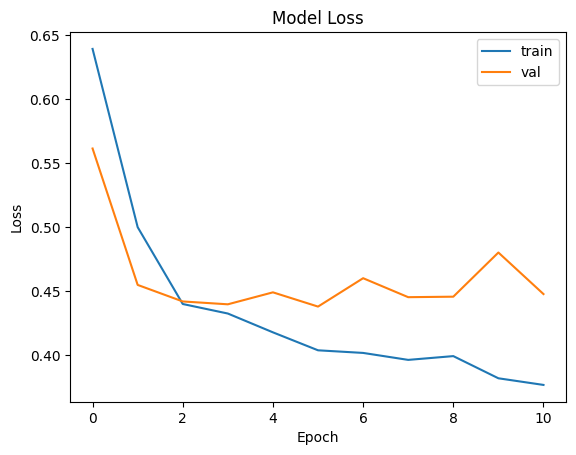

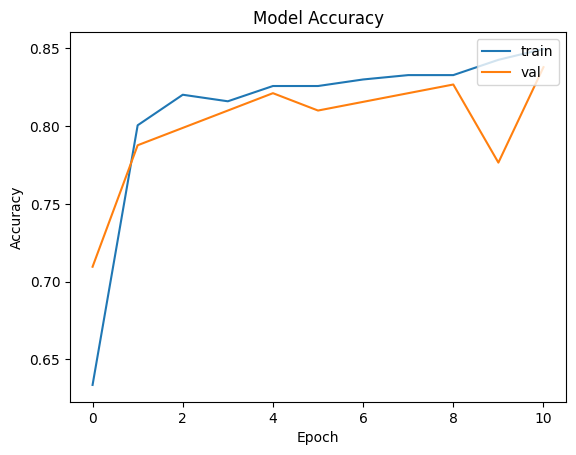

In [17]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend(['train', 'val'], loc='upper right')
plt.show()

plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend(['train', 'val'], loc='upper right')
plt.show()

- 위의 플롯에서 첫 몇 에피소드 이후에 검증 손실이 증가하기 시작하면서, 기계 학습 손실이 일관되게 감소한다는 것이 명확하게 보일 것으로 기대. 이는 과적합의 좋은 신호

## **Prepare the Test Data**

- 다시 한번, 우리는 기차 데이터에서 했던 것처럼 데이터를 삭제해야 함
- 이후 이전과 동일한 파이프라인을 사용하여 데이터를 변환해야 함
- 예측값이 0.5보다 크면 그 사람이 생존했다고 말함

In [18]:
test_df = pd.read_csv('../input/competitions/titanic/test.csv')
test_df.drop(['PassengerId', 'Name', 'Ticket', 'Cabin'], axis=1, inplace=True)
test_df

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,3,male,34.5,0,0,7.8292,Q
1,3,female,47.0,1,0,7.0000,S
2,2,male,62.0,0,0,9.6875,Q
3,3,male,27.0,0,0,8.6625,S
4,3,female,22.0,1,1,12.2875,S
...,...,...,...,...,...,...,...
413,3,male,NaN,0,0,8.0500,S
414,1,female,39.0,0,0,108.9000,C
415,3,male,38.5,0,0,7.2500,S
416,3,male,NaN,0,0,8.0500,S


In [19]:
test_prepared = full_pipeline.transform(test_df)
test_prepared.shape

(418, 12)

In [20]:
preds = model.predict(test_prepared)
preds[:5]

14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 35ms/step


array([[0.08115534],
       [0.32285067],
       [0.03659381],
       [0.10111231],
       [0.28355527]], dtype=float32)

In [21]:
submission = pd.read_csv('../input/competitions/titanic/gender_submission.csv')
submission['Survived'] = [0 if pred < 0.5 else 1 for pred in preds]
submission.head()

,PassengerId,Survived
0,892,0
1,893,0
2,894,0
3,895,0
4,896,0


In [22]:
from IPython.display import FileLink


submission.to_csv('submission.csv',index=False)
FileLink(r'submission.csv')

/kaggle/working/submission.csv